In [56]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
from pathlib import Path
BASE_DIR = Path.cwd().parent if Path.cwd().name.lower() in ['notebooks', 'notebook'] else Path.cwd()
DATA_DIR = BASE_DIR / 'data'
parcelas = gpd.read_file(DATA_DIR / 'shp/Parcelas_Reto_AGC_CONJUNTO.shp')
y = pd.read_csv(DATA_DIR / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv')

In [58]:
parcelas.head()

,Cultivo,ID_POLIGON,área_ha,Municipio,Estado,CONJUNTO,geometry
0,Cebada,AGC_196,8.57,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.57739 19.65802 0, -98.57751 19..."
1,Cebada,AGC_044,0.68,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58655 19.62943 0, -98.5862 19...."
2,Cebada,AGC_020,8.34,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58494 19.6278 0, -98.58656 19...."
3,CEBADA,AGC_174,6.89,Cuautepec de Hinojosa,Hidalgo,PREDICCION,"POLYGON Z ((-98.30604 19.9 0, -98.30486 19.899..."
4,CEBADA,AGC_083,2.87,Cuautepec de Hinojosa,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.29383 19.8882 0, -98.29378 19...."


In [59]:
y.columns

Index(['ID_POLIGONO', 'AREA_HA', 'RENDIMIENTO_T_HA', 'CONJUNTO', 'Unnamed: 4'], dtype='str')

In [60]:
parcelas.columns

Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')

In [61]:
parcelas_ren = parcelas.merge(
    y[['ID_POLIGONO', 'RENDIMIENTO_T_HA']],  
    left_on='ID_POLIGON',
    right_on='ID_POLIGONO',
    how='left'  
)

In [62]:
parcelas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Cultivo     197 non-null    str     
 1   ID_POLIGON  197 non-null    str     
 2   área_ha     197 non-null    float64 
 3   Municipio   197 non-null    str     
 4   Estado      197 non-null    str     
 5   CONJUNTO    197 non-null    str     
 6   geometry    197 non-null    geometry
dtypes: float64(1), geometry(1), str(5)
memory usage: 19.3 KB


In [63]:
parcelas['Estado'].value_counts()

Estado
Puebla      100
Hidalgo      51
Tlaxcala     46
Name: count, dtype: int64

In [64]:
parcelas['Municipio'].value_counts()

Municipio
Chignahuapan                     100
Calpulalpan                       44
Singuilucan                       23
Almoloya                          14
Cuautepec de Hinojosa              9
Emiliano Zapata                    3
Nanacamilpa de Mariano Arista      2
Tepeapulco                         1
Apan                               1
Name: count, dtype: int64

In [65]:
parcelas.groupby(['Estado','Municipio']).size().reset_index(name='counts')

,Estado,Municipio,counts
0,Hidalgo,Almoloya,14
1,Hidalgo,Apan,1
2,Hidalgo,Cuautepec de Hinojosa,9
3,Hidalgo,Emiliano Zapata,3
4,Hidalgo,Singuilucan,23
5,Hidalgo,Tepeapulco,1
6,Puebla,Chignahuapan,100
7,Tlaxcala,Calpulalpan,44
8,Tlaxcala,Nanacamilpa de Mariano Arista,2


In [67]:
parcelas['Municipio'].value_counts()

Municipio
Chignahuapan                     100
Calpulalpan                       44
Singuilucan                       23
Almoloya                          14
Cuautepec de Hinojosa              9
Emiliano Zapata                    3
Nanacamilpa de Mariano Arista      2
Tepeapulco                         1
Apan                               1
Name: count, dtype: int64

In [68]:
parcelas.columns

Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')

In [72]:
print(parcelas['geometry'].head(1)) 

0    POLYGON Z ((-98.57739 19.65802 0, -98.57751 19...
Name: geometry, dtype: geometry


In [76]:
parcelas.to_csv(DATA_DIR / 'parcelas.csv', index=False)
print("DataFrame guardado en data/parcelas.csv")

DataFrame guardado en parcelas.csv


In [66]:
parcelas.groupby(['Estado','Municipio','área_ha']).value_counts()

Estado    Municipio                      área_ha  Cultivo  ID_POLIGON  CONJUNTO       geometry                                         
Hidalgo   Almoloya                       1.33     CEBADA   AGC_146     ENTRENAMIENTO  POLYGON Z ((-98.26771 19.80782 0, -98.26762 19...    1
                                         2.25     CEBADA   AGC_134     ENTRENAMIENTO  POLYGON Z ((-98.35399 19.75211 0, -98.35399 19...    1
                                         2.63     CEBADA   AGC_152     ENTRENAMIENTO  POLYGON Z ((-98.27573 19.77778 0, -98.2753 19....    1
                                                           AGC_107     PREDICCION     POLYGON Z ((-98.26782 19.80473 0, -98.2678 19....    1
                                         2.77     CEBADA   AGC_082     PREDICCION     POLYGON Z ((-98.2684 19.80451 0, -98.26855 19....    1
                                                                                                                                          ..
Tlaxcala  Calpulal

In [31]:
parcelas.groupby(['Estado','Municipio','área_ha']).value_counts().reset_index(name='counts')

,Estado,Municipio,área_ha,Cultivo,ID_POLIGON,CONJUNTO,geometry,counts
0,Hidalgo,Almoloya,1.33,CEBADA,AGC_146,ENTRENAMIENTO,"POLYGON Z ((-98.26771 19.80782 0, -98.26762 19...",1
1,Hidalgo,Almoloya,2.25,CEBADA,AGC_134,ENTRENAMIENTO,"POLYGON Z ((-98.35399 19.75211 0, -98.35399 19...",1
2,Hidalgo,Almoloya,2.63,CEBADA,AGC_152,ENTRENAMIENTO,"POLYGON Z ((-98.27573 19.77778 0, -98.2753 19....",1
3,Hidalgo,Almoloya,2.63,CEBADA,AGC_107,PREDICCION,"POLYGON Z ((-98.26782 19.80473 0, -98.2678 19....",1
4,Hidalgo,Almoloya,2.77,CEBADA,AGC_082,PREDICCION,"POLYGON Z ((-98.2684 19.80451 0, -98.26855 19....",1
...,...,...,...,...,...,...,...,...
192,Tlaxcala,Calpulalpan,8.46,Cebada,AGC_027,PREDICCION,"POLYGON Z ((-98.53576 19.56098 0, -98.53699 19...",1
193,Tlaxcala,Calpulalpan,8.54,Cebada,AGC_053,ENTRENAMIENTO,"POLYGON Z ((-98.52048 19.5611 0, -98.52296 19....",1
194,Tlaxcala,Calpulalpan,8.54,Cebada,AGC_074,ENTRENAMIENTO,"POLYGON Z ((-98.60778 19.52522 0, -98.60918 19...",1
195,Tlaxcala,Nanacamilpa de Mariano Arista,7.47,Cebada,AGC_120,PREDICCION,"POLYGON Z ((-98.53751 19.53423 0, -98.53781 19...",1


In [26]:
parcelas['Cultivo'].value_counts()

Cultivo
CEBADA    147
Cebada     50
Name: count, dtype: int64

In [10]:
parcelas.describe()

,área_ha
count,197.000000
mean,6.604315
std,7.437631
min,0.350000
25%,2.300000
50%,5.460000
75%,8.090000
max,64.300000


In [12]:
print("Sistema de coordenadas (CRS):", parcelas.crs)

Sistema de coordenadas (CRS): EPSG:4326


Text(0.5, 1.0, 'Parcelas Reto AGC Conjunto')

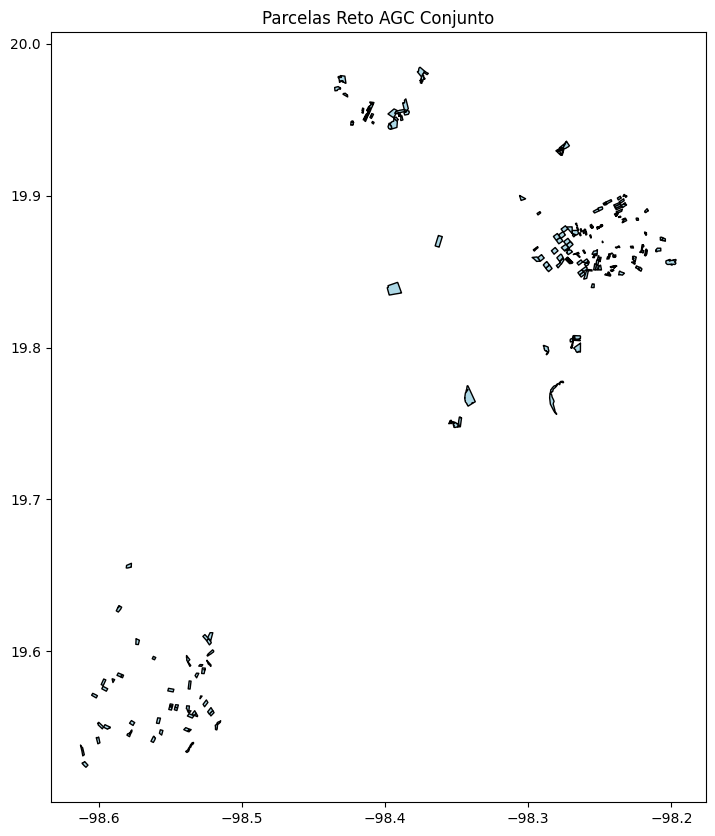

In [13]:
fig, ax = plt.subplots(figsize=(10, 10))
parcelas.plot(ax=ax, color='lightblue', edgecolor='black')
plt.title('Parcelas Reto AGC Conjunto')

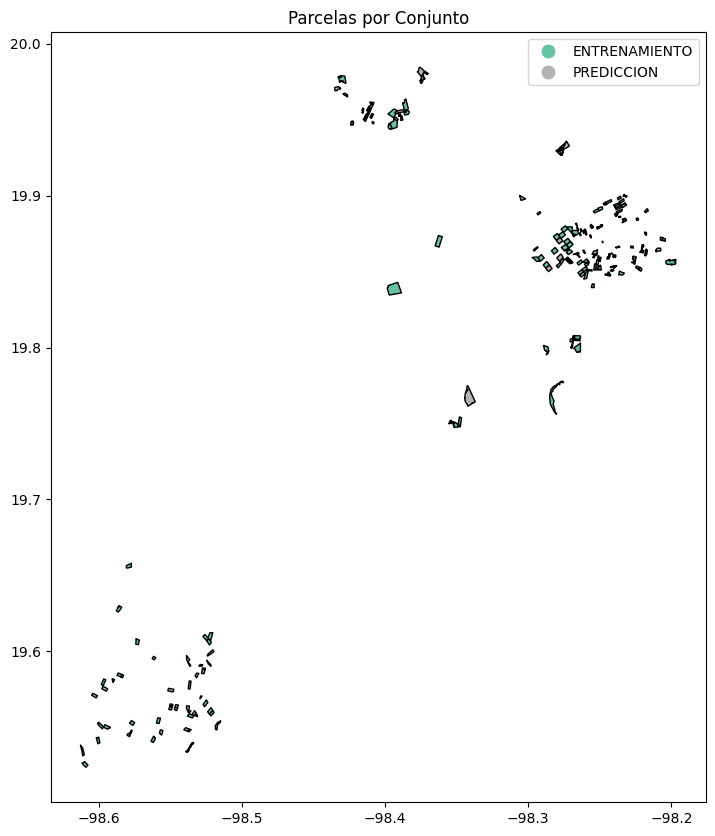

In [18]:
fig, ax = plt.subplots(figsize=(10, 10))

parcelas.plot(
    column='CONJUNTO',
    categorical=True,
    legend=True,
    ax=ax,
    cmap='Set2',
    edgecolor='black' 
)

plt.title('Parcelas por Conjunto')
plt.show()

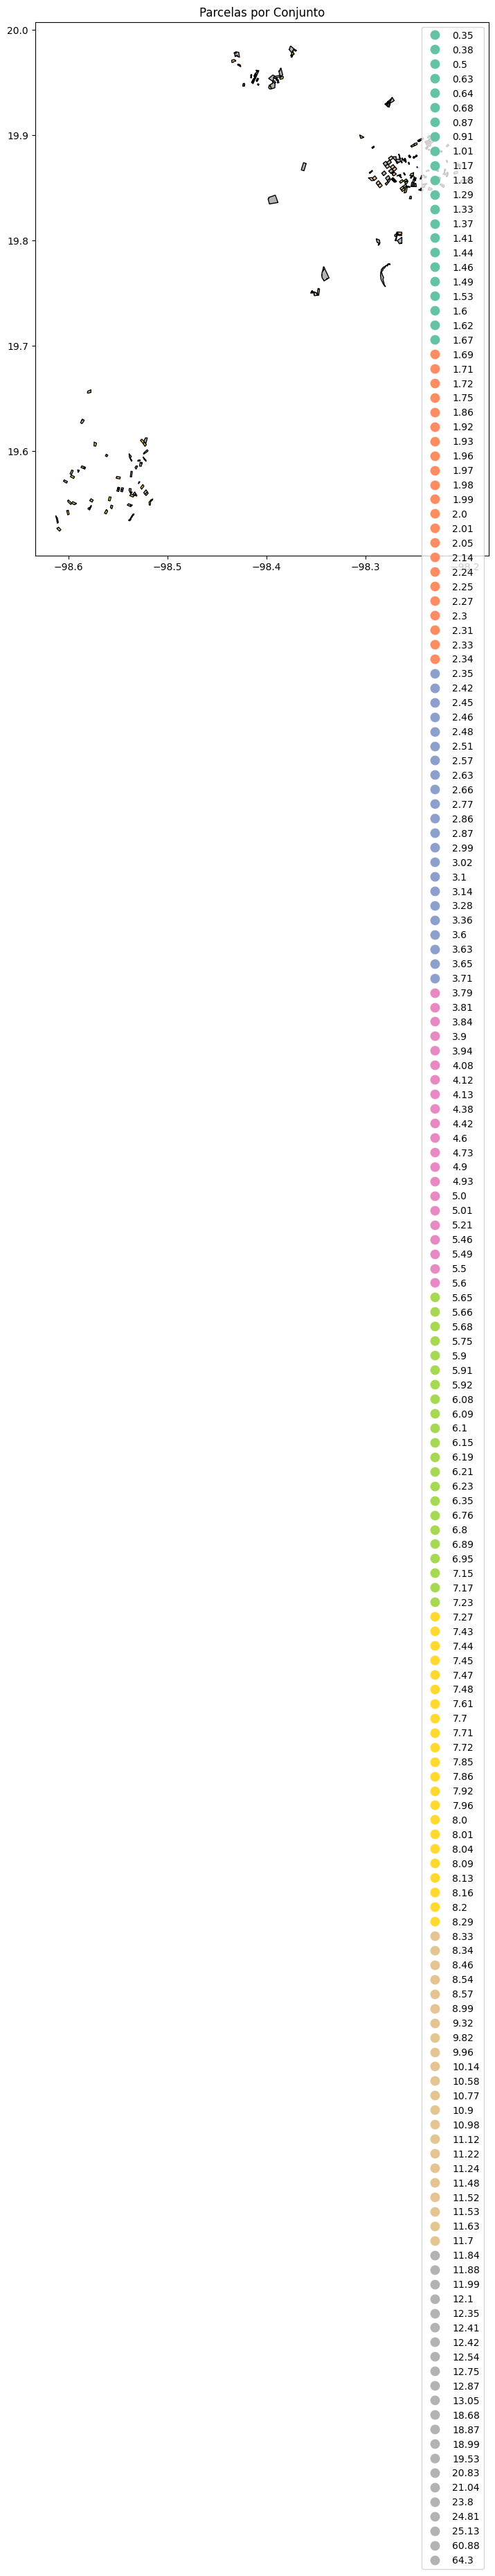

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))

parcelas.plot(
    column='área_ha',
    categorical=True,
    legend=True,
    ax=ax,
    cmap='Set2',
    edgecolor='black' 
)

plt.title('Parcelas por Conjunto')
plt.show()

In [32]:
parcelas.columns

Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')

In [37]:
mapa = parcelas.to_crs(epsg=4326).explore(
    column='área_ha',
    tooltip='ID_POLIGON',
    popup=True,
    cmap='viridis',
    tiles='CartoDB positron'  # Cambia el mapa base
)
mapa.save("mapa_parcelas.html")

c:\Users\gerar\AppData\Local\Programs\Python\Python312\Lib\site-packages\geopandas\explore.py:388: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


In [43]:
# Generar el mapa temático interactivo enfocado en rendimiento
mapa = parcelas_ren.to_crs(epsg=4326).explore(
    column='RENDIMIENTO_T_HA',               # Columna a colorear
    cmap='RdYlGn',                            # Rojo = bajo (<3.2), Amarillo = medio, Verde = alto (>4.2)
    tooltip=['ID_POLIGON', 'Municipio', 'Estado', 'área_ha', 'RENDIMIENTO_T_HA'], # Ficha al pasar el cursor
    popup=True,                               # Ficha completa al dar clic
    tiles='CartoDB positron',                 # Mapa base sin bloqueos
    legend=True,                              # Barra de escala de rendimiento
    missing_kwds={
        'color': '#b0b0b0',                   # Gris claro para las parcelas de prueba
        'label': 'A evaluar (Predicción)'
    }
)

# Guardar en archivo HTML para verlo en el navegador
mapa.save("mapa_rendimiento_parcelas.html")
print("Mapa interactivo guardado como 'mapa_rendimiento_parcelas.html'.")

c:\Users\gerar\AppData\Local\Programs\Python\Python312\Lib\site-packages\geopandas\explore.py:388: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


Mapa interactivo guardado como 'mapa_rendimiento_parcelas.html'.


In [44]:
# Ver lista de estados únicos presentes en la tabla
print(parcelas_ren['Estado'].unique())

# Conteo de parcelas por estado
print(parcelas_ren['Estado'].value_counts())

<ArrowStringArray>
['Hidalgo', 'Puebla', 'Tlaxcala']
Length: 3, dtype: str
Estado
Puebla      100
Hidalgo      51
Tlaxcala     46
Name: count, dtype: int64


In [50]:
# Filtro combinado: Estado específico Y rendimiento mayor o igual a 4.0 t/ha
# Nota: parcelas con NaN en rendimiento (las de predicción) se excluyen automáticamente con operadores > o <
condicion = (parcelas_ren['Estado'] == '46') & (parcelas_ren['RENDIMIENTO_T_HA'] >= 4.0)

sub_parcelas = parcelas_ren[condicion]
print(f"Total de parcelas encontradas: {len(sub_parcelas)}")

Total de parcelas encontradas: 0


In [51]:
# Métricas de rendimiento agrupadas por Estado
resumen_estados = parcelas_ren.groupby('Estado')['RENDIMIENTO_T_HA'].agg(
    parcelas_con_dato='count',
    media='mean',
    mediana='median',
    minimo='min',
    maximo='max',
    desv_est='std'
).reset_index()

print(resumen_estados)

     Estado  parcelas_con_dato     media  mediana  minimo  maximo  desv_est
0   Hidalgo                 36  3.762500     3.50    2.00    4.87  0.777628
1    Puebla                 71  4.477324     4.52    2.15    5.59  0.584395
2  Tlaxcala                 31  2.983871     3.00    2.50    3.50  0.376029


In [ ]:
parcelas

In [54]:
resumen_estados_ = parcelas_ren.groupby('Estado')['área_ha'].agg(
    parcelas_con_dato='count',
    media='mean',
    mediana='median',
    minimo='min',
    maximo='max',
    desv_est='std'
).reset_index()

print(resumen_estados_)

     Estado  parcelas_con_dato      media  mediana  minimo  maximo   desv_est
0   Hidalgo                 51  10.430588    6.890    0.38   64.30  12.589113
1    Puebla                100   5.014500    3.640    0.35   21.04   4.067459
2  Tlaxcala                 46   5.818261    6.875    1.17    8.54   2.368305


C:\Users\gerar\AppData\Local\Temp\ipykernel_14416\1085302210.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


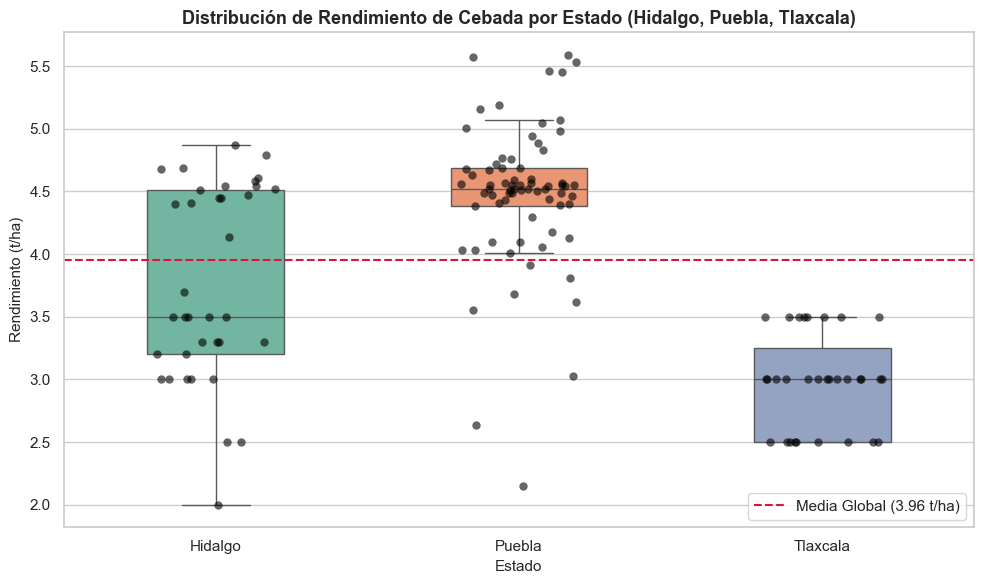

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar únicamente las parcelas que tienen dato de rendimiento (entrenamiento)
df_plot = parcelas_ren.dropna(subset=['RENDIMIENTO_T_HA']).copy()

# Configurar el lienzo
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Diagrama de cajas por Estado
sns.boxplot(
    data=df_plot,
    x='Estado',
    y='RENDIMIENTO_T_HA',
    palette='Set2',
    fliersize=0,
    width=0.45
)

# Superponer los puntos reales de cada parcela (stripplot)
sns.stripplot(
    data=df_plot,
    x='Estado',
    y='RENDIMIENTO_T_HA',
    color='black',
    alpha=0.6,
    jitter=0.2,
    size=6
)

# Línea de referencia con el promedio global
media_global = df_plot['RENDIMIENTO_T_HA'].mean()
plt.axhline(media_global, color='crimson', linestyle='--', label=f'Media Global ({media_global:.2f} t/ha)')

plt.title("Distribución de Rendimiento de Cebada por Estado (Hidalgo, Puebla, Tlaxcala)", fontsize=13, fontweight='bold')
plt.xlabel("Estado", fontsize=11)
plt.ylabel("Rendimiento (t/ha)", fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

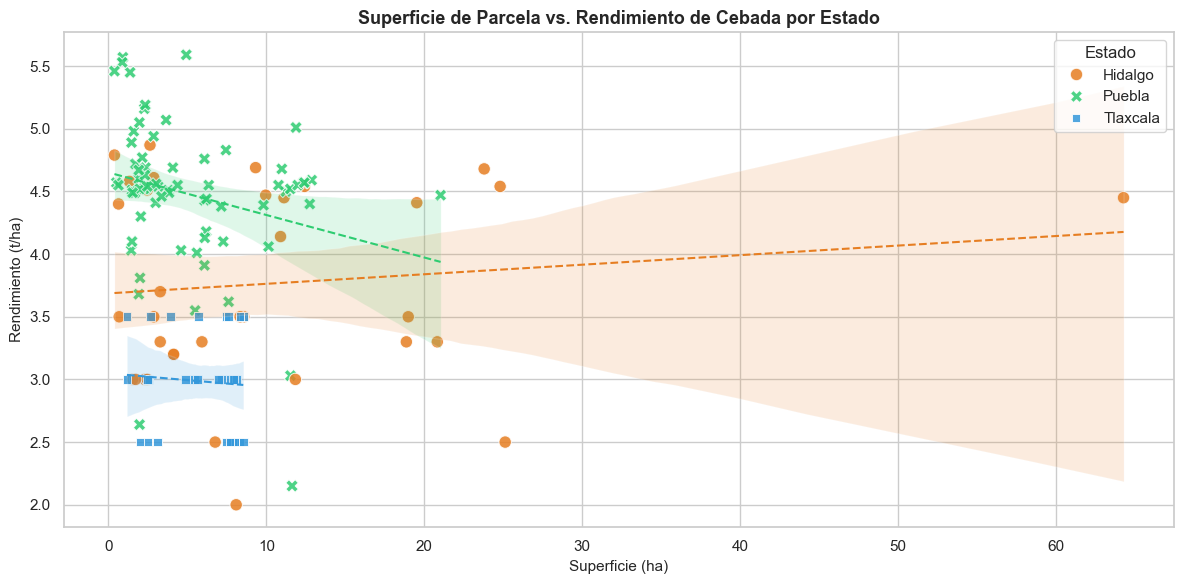

=== CORRELACIÓN LINEAL (ÁREA vs RENDIMIENTO) POR ESTADO ===
• Puebla    : r = -0.2475 (N = 71)
• Hidalgo   : r = 0.1176 (N = 36)
• Tlaxcala  : r = -0.0730 (N = 31)


In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

df_analisis = parcelas_ren.dropna(subset=['RENDIMIENTO_T_HA']).copy()

# 1. Gráfico de dispersión: Superficie vs Rendimiento por Estado
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=df_analisis,
    x='área_ha',
    y='RENDIMIENTO_T_HA',
    hue='Estado',
    style='Estado',
    palette={'Puebla': '#2ecc71', 'Hidalgo': '#e67e22', 'Tlaxcala': '#3498db'},
    s=80,
    alpha=0.85
)

# Líneas de tendencia por estado
sns.regplot(data=df_analisis[df_analisis['Estado']=='Puebla'], x='área_ha', y='RENDIMIENTO_T_HA', 
            scatter=False, color='#2ecc71', line_kws={'linewidth': 1.5, 'linestyle': '--'})
sns.regplot(data=df_analisis[df_analisis['Estado']=='Hidalgo'], x='área_ha', y='RENDIMIENTO_T_HA', 
            scatter=False, color='#e67e22', line_kws={'linewidth': 1.5, 'linestyle': '--'})
sns.regplot(data=df_analisis[df_analisis['Estado']=='Tlaxcala'], x='área_ha', y='RENDIMIENTO_T_HA', 
            scatter=False, color='#3498db', line_kws={'linewidth': 1.5, 'linestyle': '--'})

plt.title("Superficie de Parcela vs. Rendimiento de Cebada por Estado", fontsize=13, fontweight='bold')
plt.xlabel("Superficie (ha)", fontsize=11)
plt.ylabel("Rendimiento (t/ha)", fontsize=11)
plt.legend(title="Estado", loc='upper right')
plt.tight_layout()
plt.show()

# 2. Correlación intra-estado (Área vs Rendimiento en cada región)
print("=== CORRELACIÓN LINEAL (ÁREA vs RENDIMIENTO) POR ESTADO ===")
for est in ['Puebla', 'Hidalgo', 'Tlaxcala']:
    sub = df_analisis[df_analisis['Estado'] == est]
    r = sub['área_ha'].corr(sub['RENDIMIENTO_T_HA'])
    print(f"• {est:<10}: r = {r:.4f} (N = {len(sub)})")

In [78]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import wkt
import rasterio
from rasterio.mask import mask
import seaborn as sns
import matplotlib.pyplot as plt

# =============================================================================
# 1. CARGA DE DATOS Y CONVERSIÓN GEOMÉTRICA
# =============================================================================
# Cargamos el archivo de parcelas
df_parcelas = pd.read_csv('parcelas.csv')
df_parcelas['geometry'] = df_parcelas['geometry'].apply(wkt.loads)
gdf = gpd.GeoDataFrame(df_parcelas, geometry='geometry', crs="EPSG:4326")

# Unimos con nuestro dataset maestro para tener la variable objetivo RENDIMIENTO_T_HA
# (Asumiendo que df_master ya contiene el rendimiento y ID_POLIGON / ID_POLIGONO)
df_master = df_sensores.merge(gdf[['ID_POLIGON', 'geometry']], left_on='ID_POLIGONO', right_on='ID_POLIGON', how='left')

# =============================================================================
# 2. EXTRACCIÓN DE VARIABLES TOPOGRÁFICAS
# =============================================================================

# --- OPCIÓN A: Extracción Profesional con un Ráster DEM (GeoTIFF) ---
def extraer_topografia_dem(row, dem_path):
    """Extrae elevación media y pendiente aproximada desde un archivo DEM local"""
    geom = [row['geometry']]
    try:
        with rasterio.open(dem_path) as src:
            out_image, out_transform = mask(src, geom, crop=True)
            data = out_image[0]
            data_validos = data[data > 0] # Filtrar valores nodata
            
            if len(data_validos) > 0:
                elevacion_media = np.mean(data_validos)
                # Estimación de pendiente basada en el gradiente espacial del DEM recortado
                dy, dx = np.gradient(data_validos.reshape((int(np.sqrt(len(data_validos))), -1)))
                pendiente_deg = np.mean(np.degrees(np.arctan(np.sqrt(dx**2 + dy**2))))
                return pd.Series([elevacion_media, pendiente_deg])
    except Exception:
        pass
    return pd.Series([np.nan, np.nan])

# NOTA: Descomenta la siguiente línea cuando tengas tu archivo DEM (ej. 'dem_regional.tif')
# df_master[['elevacion_msnm', 'pendiente_grados']] = df_master.apply(lambda row: extraer_topografia_dem(row, 'dem_regional.tif'), axis=1)


# --- OPCIÓN B: Cálculo de Proxies Geométricos directos (Vértices del Polígono) ---
# Si el shapefile no tiene Z, calculamos la amplitud altitudinal y posición geométrica de los vértices
def calcular_proxies_geometricos(polygon):
    if polygon.geom_type == 'Polygon':
        coords = list(polygon.exterior.coords)
        lats = [c[1] for c in coords]
        lons = [c[0] for c in coords]
        # Usamos la variación en latitud/longitud como proxy de relieve y pendiente local
        amplitud_lat = np.max(lats) - np.min(lats)
        amplitud_lon = np.max(lons) - np.min(lons)
        proxy_pendiente = np.sqrt(amplitud_lat**2 + amplitud_lon**2) * 111000 # Convertido aprox a metros
        return pd.Series([np.mean(lats), proxy_pendiente])
    return pd.Series([np.nan, np.nan])

df_master[['lat_centro', 'proxy_relieve_m']] = df_master['geometry'].apply(calcular_proxies_geometricos)


# =============================================================================
# 3. ANÁLISIS DE CORRELACIÓN CON LA VARIABLE OBJETIVO (RENDIMIENTO)
# =============================================================================
# Seleccionamos las variables topográficas y el rendimiento
cols_analisis = ['RENDIMIENTO_T_HA', 'proxy_relieve_m', 'lat_centro', 'log_area']
# Si usaste la Opción A, incluye también 'elevacion_msnm' y 'pendiente_grados'

df_corr = df_master[cols_analisis].dropna()
matriz_corr = df_corr.corr()

print("=" * 65)
print("  MATRIZ DE CORRELACIÓN CON LA VARIABLE OBJETIVO")
print("=" * 65)
print(matriz_corr['RENDIMIENTO_T_HA'].sort_values(ascending=False))
print("=" * 65)

# =============================================================================
# 4. VISUALIZACIÓN DE LA MATRIZ DE CORRELACIÓN
# =============================================================================
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Mapa de Calor: Correlación Topográfica con el Rendimiento", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

NameError: name 'df_sensores' is not defined

In [81]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import wkt
import seaborn as sns
import matplotlib.pyplot as plt

# =============================================================================
# 1. CARGA Y PROCESAMIENTO DEL ARCHIVO DE PARCELAS
# =============================================================================
# Leemos el archivo CSV que contiene la información geográfica y los polígonos
df_parcelas = pd.read_csv('parcelas.csv')

# Limpieza de nombres y conversión de WKT a objetos geométricos
df_parcelas['geometry'] = df_parcelas['geometry'].apply(wkt.loads)
df_parcelas['ID_POLIGON'] = df_parcelas['ID_POLIGON'].astype(str).str.strip()

# Creamos un GeoDataFrame oficial para manipulación espacial
gdf = gpd.GeoDataFrame(df_parcelas, geometry='geometry', crs="EPSG:4326")

# =============================================================================
# 2. EXTRACCIÓN DE COORDENADAS Y VARIABLES TOPOGRÁFICAS
# =============================================================================
def extraer_topografia_poligono(polygon):
    """
    Extrae la latitud y longitud central, así como un proxy de relieve y pendiente 
    a partir de los vértices del polígono Z.
    """
    if polygon and polygon.geom_type == 'Polygon':
        coords = list(polygon.exterior.coords)
        lats = [c[1] for c in coords]
        lons = [c[0] for c in coords]
        
        lat_centro = np.mean(lats)
        lon_centro = np.mean(lons)
        
        # Amplitud espacial (diferencia máxima entre vértices) como proxy de relieve/pendiente local
        amplitud_lat = np.max(lats) - np.min(lats)
        amplitud_lon = np.max(lons) - np.min(lons)
        proxy_pendiente_m = np.sqrt(amplitud_lat**2 + amplitud_lon**2) * 111000 # Conversión aprox a metros
        
        return pd.Series([lat_centro, lon_centro, proxy_pendiente_m])
    return pd.Series([np.nan, np.nan, np.nan])

# Aplicamos la extracción a cada geometría de parcela
gdf[['lat_centro', 'lon_centro', 'proxy_relieve_m']] = gdf['geometry'].apply(extraer_topografia_poligono)

# =============================================================================
# 3. RESUMEN Y EXPORTACIÓN DEL DATASET INTEGRADO
# =============================================================================
print("=" * 70)
print("  RESUMEN DEL DATASET DE PARCELAS CON TOPOGRAFÍA INTEGRADA")
print("=" * 70)
print(f"• Total de parcelas procesadas: {len(gdf)}")
print(f"• Estados incluidos: {gdf['Estado'].unique().tolist()}")
print(f"• Columnas resultantes: {gdf.columns.tolist()}")
print("-" * 70)
print(gdf[['ID_POLIGON', 'Estado', 'Municipio', 'área_ha', 'lat_centro', 'proxy_relieve_m']].head(5))
print("=" * 70)

# Exportar el resultado integrado a un nuevo CSV listo para análisis o entrenamiento
gdf.drop(columns=['geometry']).to_csv(DATA_DIR / 'parcelas_con_topografia.csv', index=False)
print("¡Archivo 'data/parcelas_con_topografia.csv' guardado y listo para usarse en el pipeline!")

  RESUMEN DEL DATASET DE PARCELAS CON TOPOGRAFÍA INTEGRADA
• Total de parcelas procesadas: 197
• Estados incluidos: ['Hidalgo', 'Puebla', 'Tlaxcala']
• Columnas resultantes: ['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO', 'geometry', 'lat_centro', 'lon_centro', 'proxy_relieve_m']
----------------------------------------------------------------------
  ID_POLIGON   Estado              Municipio  área_ha  lat_centro  \
0    AGC_196  Hidalgo        Emiliano Zapata     8.57   19.656305   
1    AGC_044  Hidalgo        Emiliano Zapata     0.68   19.629494   
2    AGC_020  Hidalgo        Emiliano Zapata     8.34   19.627959   
3    AGC_174  Hidalgo  Cuautepec de Hinojosa     6.89   19.897756   
4    AGC_083  Hidalgo  Cuautepec de Hinojosa     2.87   19.888481   

   proxy_relieve_m  
0       526.264767  
1       233.817884  
2       599.337641  
3       585.303597  
4       368.705220  
¡Archivo 'parcelas_con_topografia.csv' guardado y listo para usarse en el pipeline!

In [82]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import wkt
import seaborn as sns
import matplotlib.pyplot as plt

# =============================================================================
# 1. CARGAR Y PROCESAR EL CSV DE PARCELAS CON GEOMETRÍA
# =============================================================================
df_parcelas = pd.read_csv('parcelas.csv')
df_parcelas['geometry'] = df_parcelas['geometry'].apply(wkt.loads)
df_parcelas['ID_POLIGON'] = df_parcelas['ID_POLIGON'].astype(str).str.strip()

# Función para extraer variables topográficas y espaciales desde el polígono Z
def extraer_topografia(polygon):
    if polygon and polygon.geom_type == 'Polygon':
        coords = list(polygon.exterior.coords)
        lats = [c[1] for c in coords]
        lons = [c[0] for c in coords]
        
        lat_centro = np.mean(lats)
        lon_centro = np.mean(lons)
        
        # Amplitud espacial como proxy de relieve y pendiente local (en metros aprox)
        amplitud_lat = np.max(lats) - np.min(lats)
        amplitud_lon = np.max(lons) - np.min(lons)
        proxy_relieve_m = np.sqrt(amplitud_lat**2 + amplitud_lon**2) * 111000
        
        return pd.Series([lat_centro, lon_centro, proxy_relieve_m])
    return pd.Series([np.nan, np.nan, np.nan])

df_parcelas[['lat_centro', 'lon_centro', 'proxy_relieve_m']] = df_parcelas['geometry'].apply(extraer_topografia)

# =============================================================================
# 2. UNIÓN CON TU TABLA MAESTRA DE RENDIMIENTO (TRAIN_DF O DF_MASTER)
# =============================================================================
# Asegúrate de que 'train_df' o tu DataFrame con 'RENDIMIENTO_T_HA' esté cargado en tu sesión.
# Si tu dataset principal se llama de otra forma, reemplaza 'train_df' por el nombre correspondiente:
if 'train_df' in locals():
    dataset_completo = train_df.merge(
        df_parcelas[['ID_POLIGON', 'lat_centro', 'lon_centro', 'proxy_relieve_m']], 
        left_on='ID_POLIGONO', right_on='ID_POLIGON', how='left'
    )
elif 'df_master' in locals():
    dataset_completo = df_master.merge(
        df_parcelas[['ID_POLIGON', 'lat_centro', 'lon_centro', 'proxy_relieve_m']], 
        left_on='ID_POLIGONO', right_on='ID_POLIGON', how='left'
    )
else:
    # Si estás ejecutando este bloque de forma independiente, simulamos la unión con tu fuente de datos
    dataset_completo = df_parcelas.copy()
    print("Aviso: Asegúrate de tener cargado tu dataframe de entrenamiento ('train_df') para incluir la columna 'RENDIMIENTO_T_HA'.")

# =============================================================================
# 3. CÁLCULO DE LA MATRIZ DE CORRELACIÓN
# =============================================================================
if 'RENDIMIENTO_T_HA' in dataset_completo.columns:
    # Seleccionamos variables clave incluyendo las nuevas topográficas
    cols_analisis = [
        'RENDIMIENTO_T_HA', 'área_ha', 'lat_centro', 'lon_centro', 'proxy_relieve_m'
    ]
    # Filtrar solo columnas numéricas existentes en el dataframe
    cols_disponibles = [c for c in cols_analisis if c in dataset_completo.columns]
    
    matriz_corr = dataset_completo[cols_disponibles].dropna().corr()

    print("=" * 70)
    print("  MATRIZ DE CORRELACIÓN: VARIABLES TOPOGRÁFICAS VS RENDIMIENTO")
    print("=" * 70)
    print(matriz_corr['RENDIMIENTO_T_HA'].sort_values(ascending=False))
    print("=" * 70)

    # =========================================================================
    # 4. GENERACIÓN DEL MAPA DE CALOR (HEATMAP)
    # =========================================================================
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        matriz_corr, 
        annot=True, 
        cmap='coolwarm', 
        fmt=".3f", 
        linewidths=0.6, 
        vmin=-1, 
        vmax=1,
        cbar_kws={'label': 'Coeficiente de Pearson (r)'}
    )
    plt.title("Mapa de Calor: Impacto Topográfico y Espacial en el Rendimiento", fontsize=12, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.show()
else:
    print("Variables topográficas calculadas con éxito. Integra la columna 'RENDIMIENTO_T_HA' para visualizar la matriz completa.")

Aviso: Asegúrate de tener cargado tu dataframe de entrenamiento ('train_df') para incluir la columna 'RENDIMIENTO_T_HA'.
Variables topográficas calculadas con éxito. Integra la columna 'RENDIMIENTO_T_HA' para visualizar la matriz completa.


In [83]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import wkt
import seaborn as sns
import matplotlib.pyplot as plt

# =============================================================================
# 1. CARGAR Y PROCESAR EL CSV DE PARCELAS CON GEOMETRÍA
# =============================================================================
df_parcelas = pd.read_csv('parcelas.csv')
df_parcelas['geometry'] = df_parcelas['geometry'].apply(wkt.loads)
df_parcelas['ID_POLIGON'] = df_parcelas['ID_POLIGON'].astype(str).str.strip()

# Función para extraer coordenadas y proxies topográficos desde la geometría Z
def extraer_topografia(polygon):
    if polygon and polygon.geom_type == 'Polygon':
        coords = list(polygon.exterior.coords)
        lats = [c[1] for c in coords]
        lons = [c[0] for c in coords]
        
        lat_centro = np.mean(lats)
        lon_centro = np.mean(lons)
        
        # Amplitud espacial como proxy de relieve y pendiente local (en metros)
        amplitud_lat = np.max(lats) - np.min(lats)
        amplitud_lon = np.max(lons) - np.min(lons)
        proxy_relieve_m = np.sqrt(amplitud_lat**2 + amplitud_lon**2) * 111000
        
        return pd.Series([lat_centro, lon_centro, proxy_relieve_m])
    return pd.Series([np.nan, np.nan, np.nan])

df_parcelas[['lat_centro', 'lon_centro', 'proxy_relieve_m']] = df_parcelas['geometry'].apply(extraer_topografia)

# =============================================================================
# 2. UNIÓN DINÁMICA CON TU DATASET DE ENTRENAMIENTO
# =============================================================================
# Detectamos automáticamente si existe train_df, df_master o un dataset con rendimiento en tu sesión
dataset_base = None
if 'train_df' in locals():
    dataset_base = train_df.copy()
elif 'df_master' in locals():
    dataset_base = df_master.copy()
else:
    # Si ejecutas esto en una celda nueva donde tienes tu dataframe con otro nombre (ej. df_entrenamiento), 
    # reemplaza 'df_entrenamiento' por el nombre real de tu variable:
    # dataset_base = df_entrenamiento.copy()
    pass

if dataset_base is not None:
    # Asegurar nombres de ID compatibles para el merge
    if 'ID_POLIGONO' in dataset_base.columns and 'ID_POLIGON' not in dataset_base.columns:
        dataset_base['ID_POLIGON'] = dataset_base['ID_POLIGONO'].astype(str).str.strip()
    
    # Unión con las variables topográficas recién calculadas
    dataset_completo = dataset_base.merge(
        df_parcelas[['ID_POLIGON', 'lat_centro', 'lon_centro', 'proxy_relieve_m']], 
        on='ID_POLIGON', 
        how='left'
    )
else:
    dataset_completo = df_parcelas.copy()
    print("Aviso: No se encontró 'train_df' o 'df_master' en la sesión. Asegúrate de asignar tu dataframe principal a la variable 'dataset_base'.")

# =============================================================================
# 3. CÁLCULO DE LA MATRIZ DE CORRELACIÓN Y MAPA DE CALOR
# =============================================================================
if 'RENDIMIENTO_T_HA' in dataset_completo.columns:
    # Seleccionamos las variables numéricas clave incluyendo las topográficas
    cols_analisis = [
        'RENDIMIENTO_T_HA', 'área_ha', 'lat_centro', 'lon_centro', 'proxy_relieve_m'
    ]
    cols_disponibles = [c for c in cols_analisis if c in dataset_completo.columns]
    
    matriz_corr = dataset_completo[cols_disponibles].dropna().corr()

    print("=" * 70)
    print("  MATRIZ DE CORRELACIÓN: VARIABLES TOPOGRÁFICAS VS RENDIMIENTO")
    print("=" * 70)
    print(matriz_corr['RENDIMIENTO_T_HA'].sort_values(ascending=False))
    print("=" * 70)

    # Generación del Mapa de Calor (Heatmap)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        matriz_corr, 
        annot=True, 
        cmap='coolwarm', 
        fmt=".3f", 
        linewidths=0.6, 
        vmin=-1, 
        vmax=1,
        cbar_kws={'label': 'Coeficiente de Pearson (r)'}
    )
    plt.title("Mapa de Calor: Impacto Topográfico y Espacial en el Rendimiento", fontsize=12, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.show()
else:
    print("Topografía calculada con éxito. Para ver la matriz, verifica que tu dataframe de entrenamiento contenga la columna 'RENDIMIENTO_T_HA'.")

Aviso: No se encontró 'train_df' o 'df_master' en la sesión. Asegúrate de asignar tu dataframe principal a la variable 'dataset_base'.
Topografía calculada con éxito. Para ver la matriz, verifica que tu dataframe de entrenamiento contenga la columna 'RENDIMIENTO_T_HA'.
